In [6]:
from google.colab import drive
folder = "data"

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [8]:
limits_flow= pd.read_csv(folder+"/day-ahead-constraints-limits-and-flow-output-v1.5.csv")
cost2024_25= pd.read_csv(folder+"/outturn-system-costs-2024-2025.csv")
cost2025_26= pd.read_csv(folder+"/outturn-system-costs-2025-2026.csv")


In [9]:
limits_flow.shape

(723057, 4)

In [10]:
limits_flow.head()

,Constraint Group,Date_ Time GMT_BST,Limit_MW,Flow_MW
0,ESTEX,2023-01-01T00:00:00,3950.0,894.0
1,ESTEX,2023-01-01T00:30:00,3950.0,919.0
2,ESTEX,2023-01-01T01:00:00,3950.0,927.0
3,ESTEX,2023-01-01T01:30:00,3950.0,937.0
4,ESTEX,2023-01-01T02:00:00,3950.0,946.0


In [11]:
limits_flow.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 723057 entries, 0 to 723056
Data columns (total 4 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Constraint Group    723057 non-null  object 
 1   Date_ Time GMT_BST  723057 non-null  object 
 2   Limit_MW            719779 non-null  float64
 3   Flow_MW             719692 non-null  float64
dtypes: float64(2), object(2)
memory usage: 22.1+ MB


In [12]:
for column in limits_flow.columns:
  print (column)

Constraint Group
Date_ Time GMT_BST
Limit_MW
Flow_MW


In [13]:
scotex= limits_flow[limits_flow['Constraint Group']=="SCOTEX"]


In [14]:
scotex.shape

(64138, 4)

In [15]:
scotex.head()

,Constraint Group,Date_ Time GMT_BST,Limit_MW,Flow_MW
144,SCOTEX,2023-01-01T00:00:00,6000.0,1253.0
145,SCOTEX,2023-01-01T00:30:00,6000.0,1253.0
146,SCOTEX,2023-01-01T01:00:00,6000.0,1230.0
147,SCOTEX,2023-01-01T01:30:00,6000.0,1236.0
148,SCOTEX,2023-01-01T02:00:00,6000.0,1130.0


In [16]:

scotex_2025=scotex[
    scotex["Date_ Time GMT_BST"].str.startswith("2025")]

In [17]:
scotex_2025.shape

(17520, 4)

In [18]:
scotex_2025.head()

,Constraint Group,Date_ Time GMT_BST,Limit_MW,Flow_MW
352557,SCOTEX,2025-01-01T00:00:00,6200.0,7990.0
352558,SCOTEX,2025-01-01T00:30:00,6200.0,7740.0
352559,SCOTEX,2025-01-01T01:00:00,6200.0,7644.0
352560,SCOTEX,2025-01-01T01:30:00,6200.0,7514.0
352561,SCOTEX,2025-01-01T02:00:00,6200.0,7423.0


In [19]:
scotex_2025.isnull().sum()

,0
Constraint Group,0
Date_ Time GMT_BST,0
Limit_MW,0
Flow_MW,0


In [20]:
scotex_2025.duplicated().sum()

np.int64(48)

In [21]:
scotex_2025.loc[
    scotex_2025.duplicated(),
    "Date_ Time GMT_BST"
].str[:10].value_counts()

,count
Date_ Time GMT_BST,
2025-08-12,48


In [22]:
scotex_2025["Date_ Time GMT_BST"].str[:10].nunique()

364

In [23]:
expected_days = pd.date_range("2025-01-01", "2025-12-31")
actual_days = pd.to_datetime(scotex_2025["Date_ Time GMT_BST"].str[:10].unique())

expected_days.difference(actual_days)

DatetimeIndex(['2025-08-11'], dtype='datetime64[ns]', freq='D')

In [24]:
scotex_2025_clean=scotex_2025.drop_duplicates().copy()
scotex_2025_clean.shape

(17472, 4)

In [25]:
(scotex_2025_clean['Flow_MW']>scotex_2025_clean['Limit_MW']).sum()

np.int64(5483)

In [26]:
percentage=5483/len(scotex_2025_clean)*100
print(f"{percentage:.1f}%")

31.4%


Adding a new column to see the difference between flow and limit

In [27]:
scotex_2025_clean["Difference_MW"]=(scotex_2025_clean["Flow_MW"]-scotex_2025_clean["Limit_MW"])
scotex_2025_clean[["Flow_MW","Limit_MW","Difference_MW"]].head()

,Flow_MW,Limit_MW,Difference_MW
352557,7990.0,6200.0,1790.0
352558,7740.0,6200.0,1540.0
352559,7644.0,6200.0,1444.0
352560,7514.0,6200.0,1314.0
352561,7423.0,6200.0,1223.0


In [28]:
scotex_2025_clean['Difference_MW'].max()

7529.0

In [29]:
scotex_2025_clean.loc[scotex_2025_clean['Difference_MW'].idxmax()]

,379496
Constraint Group,SCOTEX
Date_ Time GMT_BST,2025-02-21T05:30:00
Limit_MW,2600.0
Flow_MW,10129.0
Difference_MW,7529.0


In [30]:
scotex_2025_clean.loc[379493:379510,["Date_ Time GMT_BST","Limit_MW","Flow_MW","Difference_MW"]]

,Date_ Time GMT_BST,Limit_MW,Flow_MW,Difference_MW
379493,2025-02-21T04:00:00,10000.0,9782.0,-218.0
379494,2025-02-21T04:30:00,10000.0,9930.0,-70.0
379495,2025-02-21T05:00:00,2600.0,10016.0,7416.0
379496,2025-02-21T05:30:00,2600.0,10129.0,7529.0
379497,2025-02-21T06:00:00,2600.0,10040.0,7440.0
379498,2025-02-21T06:30:00,2600.0,9992.0,7392.0
379499,2025-02-21T07:00:00,2600.0,10099.0,7499.0
379500,2025-02-21T07:30:00,2600.0,9960.0,7360.0
379501,2025-02-21T08:00:00,3400.0,9898.0,6498.0
379502,2025-02-21T08:30:00,3400.0,9878.0,6478.0


In [31]:
scotex_2025_clean.nlargest(
    10, "Difference_MW"
)[["Date_ Time GMT_BST", "Limit_MW", "Flow_MW", "Difference_MW"]]

,Date_ Time GMT_BST,Limit_MW,Flow_MW,Difference_MW
379496,2025-02-21T05:30:00,2600.0,10129.0,7529.0
379499,2025-02-21T07:00:00,2600.0,10099.0,7499.0
379497,2025-02-21T06:00:00,2600.0,10040.0,7440.0
379495,2025-02-21T05:00:00,2600.0,10016.0,7416.0
379498,2025-02-21T06:30:00,2600.0,9992.0,7392.0
379500,2025-02-21T07:30:00,2600.0,9960.0,7360.0
432327,2025-06-03T14:30:00,2800.0,10119.0,7319.0
432323,2025-06-03T12:30:00,2800.0,10081.0,7281.0
432326,2025-06-03T14:00:00,2800.0,10079.0,7279.0
432321,2025-06-03T11:30:00,2800.0,10048.0,7248.0


In [32]:
scotex_2025_clean.loc[432305:432335,["Date_ Time GMT_BST","Limit_MW","Flow_MW","Difference_MW"]]

,Date_ Time GMT_BST,Limit_MW,Flow_MW,Difference_MW
432305,2025-06-03T03:30:00,5350.0,9619.0,4269.0
432306,2025-06-03T04:00:00,5350.0,9096.0,3746.0
432307,2025-06-03T04:30:00,5350.0,8823.0,3473.0
432308,2025-06-03T05:00:00,5350.0,8718.0,3368.0
432309,2025-06-03T05:30:00,5350.0,8759.0,3409.0
432310,2025-06-03T06:00:00,5350.0,9112.0,3762.0
432311,2025-06-03T06:30:00,5350.0,9072.0,3722.0
432312,2025-06-03T07:00:00,5350.0,9000.0,3650.0
432313,2025-06-03T07:30:00,2800.0,9215.0,6415.0
432314,2025-06-03T08:00:00,2800.0,9256.0,6456.0


In [33]:
large_gaps = scotex_2025_clean[
    scotex_2025_clean["Difference_MW"] > 5000
].copy()

large_gaps["Date"] = large_gaps["Date_ Time GMT_BST"].str[:10]

large_gaps.groupby("Date")["Difference_MW"].agg(
    half_hours="count",
    largest_gap_MW="max"
).sort_values("largest_gap_MW", ascending=False)

,half_hours,largest_gap_MW
Date,,
2025-02-21,38,7529.0
2025-06-03,39,7319.0
2025-06-04,33,6890.0
2025-08-05,39,6654.0
2025-08-04,8,6577.0
2025-09-10,18,6540.0
2025-11-01,19,6501.0
2025-02-23,3,6371.0
2025-06-02,9,6180.0


In [34]:
june_3 = scotex_2025_clean[
    scotex_2025_clean["Date_ Time GMT_BST"].str.startswith("2025-06-03")
]
june_3.shape

(48, 5)

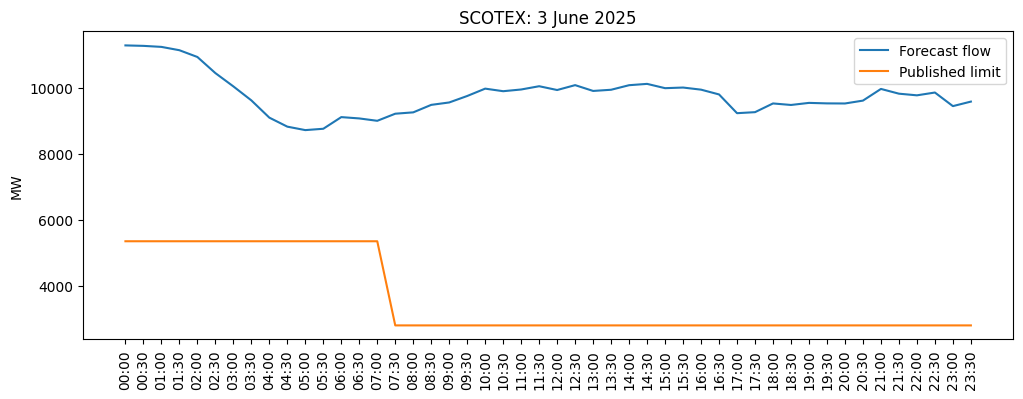

In [35]:
plt.figure(figsize=(12, 4))
plt.plot(june_3["Date_ Time GMT_BST"].str[11:16], june_3["Flow_MW"], label="Forecast flow")
plt.plot(june_3["Date_ Time GMT_BST"].str[11:16], june_3["Limit_MW"], label="Published limit")
plt.xticks(rotation=90)
plt.ylabel("MW")
plt.title("SCOTEX: 3 June 2025")
plt.legend()
plt.show()

In [36]:
scotex_2025_clean["Month"] = scotex_2025_clean["Date_ Time GMT_BST"].str[5:7]
scotex_2025_clean[["Date_ Time GMT_BST", "Month"]].head()

,Date_ Time GMT_BST,Month
352557,2025-01-01T00:00:00,01
352558,2025-01-01T00:30:00,01
352559,2025-01-01T01:00:00,01
352560,2025-01-01T01:30:00,01
352561,2025-01-01T02:00:00,01


In [37]:
scotex_2025_clean["Above_Limit"] = (
    scotex_2025_clean["Flow_MW"] > scotex_2025_clean["Limit_MW"]
)
scotex_2025_clean[["Month", "Flow_MW", "Limit_MW", "Above_Limit"]].head()

,Month,Flow_MW,Limit_MW,Above_Limit
352557,01,7990.0,6200.0,True
352558,01,7740.0,6200.0,True
352559,01,7644.0,6200.0,True
352560,01,7514.0,6200.0,True
352561,01,7423.0,6200.0,True


In [38]:
monthly_percentage = (
    scotex_2025_clean.groupby("Month")["Above_Limit"].mean() * 100
)
monthly_percentage.round(1)

,Above_Limit
Month,
01,35.3
02,34.1
03,47.1
04,15.4
05,17.4
06,35.6
07,15.6
08,24.7
09,39.4


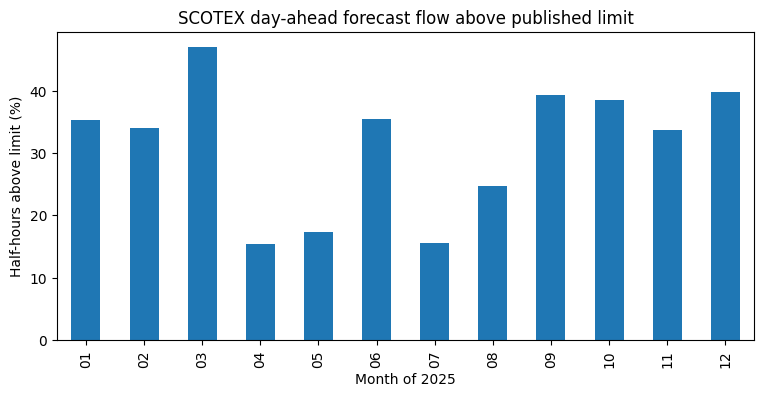

In [39]:
monthly_percentage.plot.bar(figsize=(9, 4))
plt.ylabel("Half-hours above limit (%)")
plt.xlabel("Month of 2025")
plt.title("SCOTEX day-ahead forecast flow above published limit")
plt.show()

In [40]:

cost2024_25.shape


(2190, 3)

In [41]:
cost2024_25.head()

,Settlement Date,Constraint Group,Daily Cost (GBP)
0,2024-04-01,ESTEX,0
1,2024-04-01,SCOTEX,0
2,2024-04-01,SEIMP,0
3,2024-04-01,SSE-SP,0
4,2024-04-01,SSHARN,0


In [42]:
for column in cost2024_25.columns:
  print(column)

Settlement Date
Constraint Group
Daily Cost (GBP)


In [43]:
Scotex_2024=cost2024_25[cost2024_25['Constraint Group']=="SCOTEX"]
Scotex_2024.shape

(365, 3)

In [44]:
Scotex_2024["Settlement Date"].min(),Scotex_2024["Settlement Date"].max()

('2024-04-01', '2025-03-31')

In [45]:
cost2025_26.shape

(2184, 3)

In [46]:
cost2025_26.head()

,Settlement Date,Constraint Group,Daily Cost (GBP)
0,2025-04-01,ESTEX,0
1,2025-04-01,SCOTEX,0
2,2025-04-01,SEIMP,0
3,2025-04-01,SSE-SP,145017
4,2025-04-01,SSHARN,0


In [47]:
for column in cost2025_26.columns:
  print(column)

Settlement Date
Constraint Group
Daily Cost (GBP)


In [48]:
Scotex_2025=cost2025_26[cost2025_26['Constraint Group']=="SCOTEX"]
Scotex_2025.shape

(364, 3)

In [49]:
Scotex_2025['Settlement Date'].min(),Scotex_2025['Settlement Date'].max()

('2025-04-01', '2026-03-31')

In [50]:
cost_jan_mar = Scotex_2024[
    Scotex_2024["Settlement Date"].str.startswith("2025")
]
cost_jan_mar.shape

(90, 3)

In [51]:
cost_apr_dec = Scotex_2025[
    Scotex_2025["Settlement Date"].str.startswith("2025")
]
cost_apr_dec.shape

(274, 3)

In [52]:
expected = pd.date_range("2025-04-01", "2025-12-31")
actual = pd.to_datetime(cost_apr_dec["Settlement Date"])
expected.difference(actual)

DatetimeIndex(['2025-04-08'], dtype='datetime64[ns]', freq='D')

In [53]:
scotex_cost_2025=pd.concat([cost_jan_mar, cost_apr_dec],ignore_index=True)
scotex_cost_2025.shape

(364, 3)

In [54]:
scotex_cost_2025.isna().sum()

,0
Settlement Date,0
Constraint Group,0
Daily Cost (GBP),0


In [55]:
scotex_cost_2025.duplicated(subset=["Settlement Date"]).sum()

np.int64(0)

In [56]:
scotex_cost_2025['Daily Cost (GBP)'].sum()

np.int64(157024156)

In [57]:
scotex_cost_2025["Daily Cost (GBP)"].describe()

,Daily Cost (GBP)
count,3.640000e+02
mean,4.313850e+05
std,1.393323e+06
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,1.190150e+05
max,1.349207e+07


In [58]:
scotex_cost_2025.loc[scotex_cost_2025['Daily Cost (GBP)'].idxmax()]

,51
Settlement Date,2025-02-21
Constraint Group,SCOTEX
Daily Cost (GBP),13492066


look at the flow rows for 21 February and count how many half-hours had Above_Limit == True

In [59]:
feb21 = scotex_2025_clean[
    (scotex_2025_clean["Date_ Time GMT_BST"].str.startswith("2025-02-21"))
    & (scotex_2025_clean["Above_Limit"])
]

len(feb21)

38

In [60]:
feb21[["Date_ Time GMT_BST", "Limit_MW", "Flow_MW", "Difference_MW"]]

,Date_ Time GMT_BST,Limit_MW,Flow_MW,Difference_MW
379495,2025-02-21T05:00:00,2600.0,10016.0,7416.0
379496,2025-02-21T05:30:00,2600.0,10129.0,7529.0
379497,2025-02-21T06:00:00,2600.0,10040.0,7440.0
379498,2025-02-21T06:30:00,2600.0,9992.0,7392.0
379499,2025-02-21T07:00:00,2600.0,10099.0,7499.0
379500,2025-02-21T07:30:00,2600.0,9960.0,7360.0
379501,2025-02-21T08:00:00,3400.0,9898.0,6498.0
379502,2025-02-21T08:30:00,3400.0,9878.0,6478.0
379503,2025-02-21T09:00:00,3400.0,9716.0,6316.0
379504,2025-02-21T09:30:00,3400.0,9598.0,6198.0


In [61]:
scotex_2025_clean["Date"] = scotex_2025_clean["Date_ Time GMT_BST"].str[:10]

In [62]:
scotex_2025_clean[["Date_ Time GMT_BST", "Date"]].head()

,Date_ Time GMT_BST,Date
352557,2025-01-01T00:00:00,2025-01-01
352558,2025-01-01T00:30:00,2025-01-01
352559,2025-01-01T01:00:00,2025-01-01
352560,2025-01-01T01:30:00,2025-01-01
352561,2025-01-01T02:00:00,2025-01-01


In [63]:
daily_flow = scotex_2025_clean.groupby("Date")["Above_Limit"].sum()
daily_flow.loc["2025-02-21"]

np.int64(38)

In [64]:
daily_flow.head()

,Above_Limit
Date,
2025-01-01,17
2025-01-02,14
2025-01-03,16
2025-01-04,0
2025-01-05,0


In [65]:
daily_flow=daily_flow.reset_index()
daily_flow.head()

,Date,Above_Limit
0,2025-01-01,17
1,2025-01-02,14
2,2025-01-03,16
3,2025-01-04,0
4,2025-01-05,0


In [66]:
daily_comparison=daily_flow.merge(scotex_cost_2025,
                                  left_on="Date",
                                  right_on="Settlement Date",
                                  how="outer"
                                  )

In [67]:
daily_comparison.shape

(365, 5)

In [68]:
daily_comparison.head()

,Date,Above_Limit,Settlement Date,Constraint Group,Daily Cost (GBP)
0,2025-01-01,17.0,2025-01-01,SCOTEX,191643.0
1,2025-01-02,14.0,2025-01-02,SCOTEX,0.0
2,2025-01-03,16.0,2025-01-03,SCOTEX,0.0
3,2025-01-04,0.0,2025-01-04,SCOTEX,0.0
4,2025-01-05,0.0,2025-01-05,SCOTEX,0.0


In [69]:
cost_for_merge = scotex_cost_2025.rename(
    columns={"Settlement Date": "Date"}
)

daily_comparison = daily_flow.merge(
    cost_for_merge,
    on="Date",
    how="outer"
)

daily_comparison.shape

(365, 4)

In [70]:
daily_comparison[daily_comparison.isna().any(axis=1)]

,Date,Above_Limit,Constraint Group,Daily Cost (GBP)
97,2025-04-08,0.0,NaN,NaN
222,2025-08-11,NaN,SCOTEX,0.0


In [71]:
daily_comparison[daily_comparison["Date"]=="2025-02-21"]

,Date,Above_Limit,Constraint Group,Daily Cost (GBP)
51,2025-02-21,38.0,SCOTEX,13492066.0


In [72]:
daily_comparison.nlargest(10, "Daily Cost (GBP)")

,Date,Above_Limit,Constraint Group,Daily Cost (GBP)
51,2025-02-21,38.0,SCOTEX,13492066.0
242,2025-08-31,3.0,SCOTEX,11635590.0
215,2025-08-04,22.0,SCOTEX,10929188.0
259,2025-09-17,31.0,SCOTEX,7816129.0
63,2025-03-05,48.0,SCOTEX,5906097.0
216,2025-08-05,48.0,SCOTEX,4494185.0
16,2025-01-17,39.0,SCOTEX,4306112.0
50,2025-02-20,0.0,SCOTEX,4287631.0
347,2025-12-14,48.0,SCOTEX,3675456.0
152,2025-06-02,13.0,SCOTEX,3400660.0


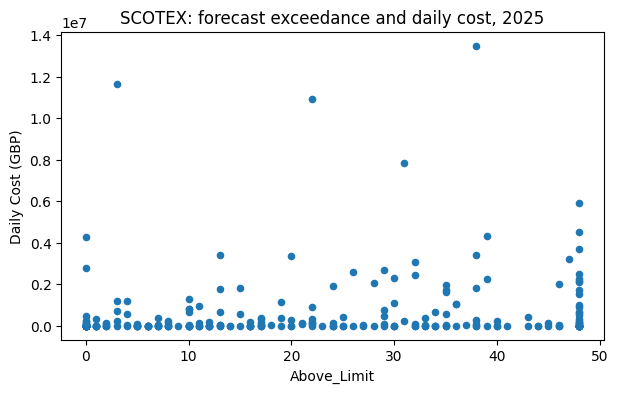

In [73]:

daily_comparison.plot.scatter(
    x="Above_Limit",
    y="Daily Cost (GBP)",
    figsize=(7,4)
)
plt.title("SCOTEX: forecast exceedance and daily cost, 2025")
plt.show()

In [74]:
scotex_cost_2025["Month"] = scotex_cost_2025["Settlement Date"].str[:7]
scotex_cost_2025[["Settlement Date", "Month", "Daily Cost (GBP)"]].head()

,Settlement Date,Month,Daily Cost (GBP)
0,2025-01-01,2025-01,191643
1,2025-01-02,2025-01,0
2,2025-01-03,2025-01,0
3,2025-01-04,2025-01,0
4,2025-01-05,2025-01,0


In [75]:
monthly_cost = scotex_cost_2025.groupby("Month")["Daily Cost (GBP)"].sum()
monthly_cost

,Daily Cost (GBP)
Month,
2025-01,14308162
2025-02,27154931
2025-03,13323885
2025-04,853358
2025-05,4868857
2025-06,9103280
2025-07,1002611
2025-08,34638250
2025-09,18742093


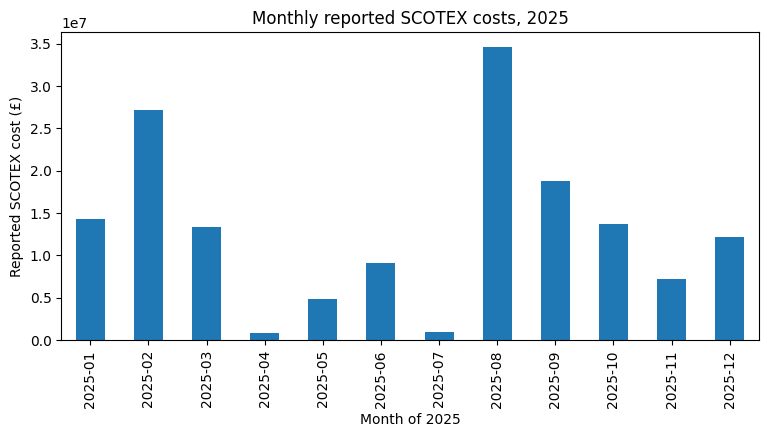

In [76]:
monthly_cost.plot.bar(figsize=(9, 4))
plt.ylabel("Reported SCOTEX cost (£)")
plt.xlabel("Month of 2025")
plt.title("Monthly reported SCOTEX costs, 2025")
plt.show()

In [77]:
scotex_cost_2025[
    scotex_cost_2025["Month"] == "2025-08"
].nlargest(5, "Daily Cost (GBP)")[
    ["Settlement Date", "Daily Cost (GBP)"]
]

,Settlement Date,Daily Cost (GBP)
241,2025-08-31,11635590
214,2025-08-04,10929188
215,2025-08-05,4494185
240,2025-08-30,3367994
216,2025-08-06,2266572


In [78]:
daily_comparison[
    daily_comparison["Date"].isin(["2025-08-04", "2025-08-31"])
][["Date", "Above_Limit", "Daily Cost (GBP)"]]

,Date,Above_Limit,Daily Cost (GBP)
215,2025-08-04,22.0,10929188.0
242,2025-08-31,3.0,11635590.0


Reported SCOTEX costs varied widely even on days with similar numbers of above-limit half-hours. The count alone cannot explain the daily cost.


In [79]:
import sqlite3

conn = sqlite3.connect(":memory:")

In [80]:
scotex_2025_clean.to_sql(
    "scotex_flow",
    conn,
    if_exists="replace",
    index=False
)

17472

In [81]:
pd.read_sql_query(
    "SELECT COUNT(*) AS total_rows FROM scotex_flow",
    conn
)

,total_rows
0,17472


In [82]:
pd.read_sql_query(
    """
    SELECT COUNT(*) AS above_limit_count
    FROM scotex_flow
    WHERE Flow_MW > Limit_MW
    """,
    conn
)

,above_limit_count
0,5483


In [83]:
pd.read_sql_query(
    """
    SELECT Date, SUM(Above_Limit) AS above_limit_count
    FROM scotex_flow
    GROUP BY Date
    HAVING SUM(Above_Limit) = 48
    ORDER BY above_limit_count DESC, Date
    """,
    conn
)

,Date,above_limit_count
0,2025-01-15,48
1,2025-01-16,48
2,2025-02-19,48
3,2025-03-04,48
4,2025-03-05,48
5,2025-03-12,48
6,2025-03-21,48
7,2025-03-22,48
8,2025-03-27,48
9,2025-03-28,48


In [84]:
scotex_cost_2025.to_sql(
    "scotex_cost",
    conn,
    if_exists="replace",
    index=False
)

364

In [85]:
pd.read_sql_query(
    """
    SELECT "Settlement Date", "Daily Cost (GBP)"
    FROM scotex_cost
    ORDER BY "Daily Cost (GBP)" DESC
    LIMIT 5
    """,
    conn
)

,Settlement Date,Daily Cost (GBP)
0,2025-02-21,13492066
1,2025-08-31,11635590
2,2025-08-04,10929188
3,2025-09-17,7816129
4,2025-03-05,5906097


In [86]:
sql_daily_comparison = pd.read_sql_query(
    """
    WITH daily_flow AS (
        SELECT Date, SUM(Above_Limit) AS above_limit_count
        FROM scotex_flow
        GROUP BY Date
    )
    SELECT
        c."Settlement Date" AS Date,
        f.above_limit_count,
        c."Daily Cost (GBP)"
    FROM scotex_cost AS c
    LEFT JOIN daily_flow AS f
        ON DATE(c."Settlement Date") = DATE(f.Date)
    ORDER BY c."Daily Cost (GBP)" DESC
    """,
    conn
)

sql_daily_comparison.head()

,Date,above_limit_count,Daily Cost (GBP)
0,2025-02-21,38.0,13492066
1,2025-08-31,3.0,11635590
2,2025-08-04,22.0,10929188
3,2025-09-17,31.0,7816129
4,2025-03-05,48.0,5906097


In [87]:
sql_daily_comparison[
    sql_daily_comparison["above_limit_count"].isna()
]

,Date,above_limit_count,Daily Cost (GBP)
294,2025-08-11,NaN,0


In [88]:
daily_comparison.columns.tolist()

['Date', 'Above_Limit', 'Constraint Group', 'Daily Cost (GBP)']

In [89]:
dashboard_daily = daily_comparison.rename(columns={
    "Above_Limit": "Above_Limit_Periods",
    "Constraint Group": "Constraint_Group",
    "Daily Cost (GBP)": "Daily_Cost_GBP"
}).copy()

dashboard_daily["Date"] = pd.to_datetime(dashboard_daily["Date"])

dashboard_daily.head()

,Date,Above_Limit_Periods,Constraint_Group,Daily_Cost_GBP
0,2025-01-01,17.0,SCOTEX,191643.0
1,2025-01-02,14.0,SCOTEX,0.0
2,2025-01-03,16.0,SCOTEX,0.0
3,2025-01-04,0.0,SCOTEX,0.0
4,2025-01-05,0.0,SCOTEX,0.0


In [90]:
dashboard_daily.to_csv(
    folder + "/scotex_daily_dashboard_2025.csv",
    index=False
)